# Problem Set 1: Linear Regression and Regularization

### 1. a) Import Housing.csv as a pandas DataFrame

In [823]:
import pandas as pd
import numpy as np

housing=pd.read_csv("Housing.csv", keep_default_na=False)
print(housing.shape)
housing.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500
3,4,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,12,2008,WD,Normal,250000


### Separate the explanatory features X from the target y = SalePrice

In [824]:
# delete two columns from the data frame.
X=housing.drop(columns=["Id", "SalePrice"])
display(X.head())
# single out the target variable
y=housing["SalePrice"]
display(y.head())

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,Inside,...,0,0,NA,NA,NA,0,2,2008,WD,Normal
1,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,FR2,...,0,0,NA,NA,NA,0,5,2007,WD,Normal
2,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,Inside,...,0,0,NA,NA,NA,0,9,2008,WD,Normal
3,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,Corner,...,0,0,NA,NA,NA,0,2,2006,WD,Abnorml
4,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,FR2,...,0,0,NA,NA,NA,0,12,2008,WD,Normal


0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

### 1. b) Graphically determine whether SalePrice is approximately Gaussian

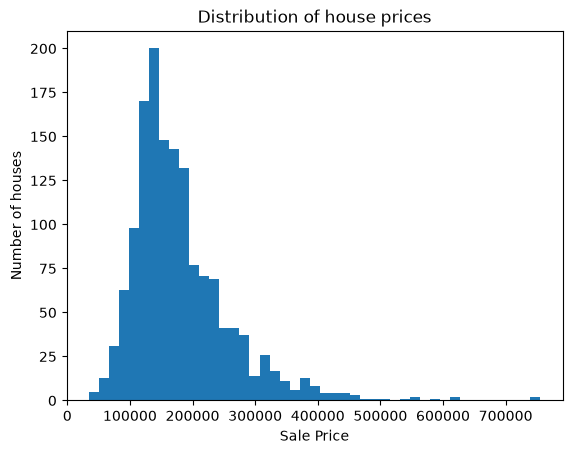

In [825]:
# split the sale prices into 45 bins
plt.hist(y,bins=45)
plt.xlabel("Sale Price")
plt.ylabel("Number of houses")
plt.title("Distribution of house prices")
plt.show()

### If it is not, suggest and apply a suitable transformation

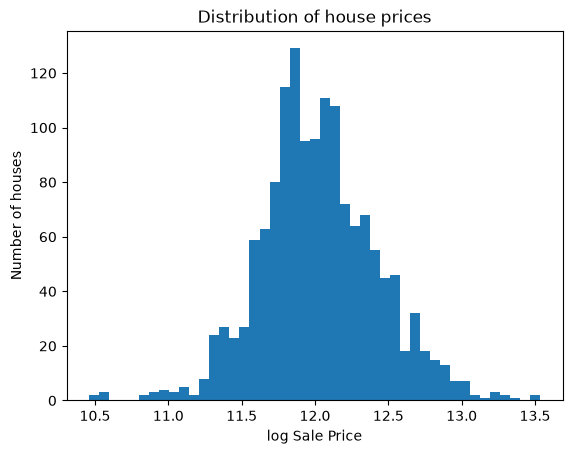

In [826]:
# take the log of the sale price
log_y=np.log(y)
plt.hist(log_y,bins=45)
plt.xlabel("log Sale Price")
plt.ylabel("Number of houses")
plt.title("Distribution of house prices")
plt.show()

### Why is it important to consider such potential transformations?
The original prices are right-skewed. The logarithm compresses the high prices, which should make the distribution more balanced.

### 1. c) Randomly assign 70% of the observations to the training set and 30% to the test set.

In [827]:
from sklearn.model_selection import train_test_split

X_train_unprocessed, X_test_unprocessed, y_train, y_test = train_test_split(X, log_y, test_size=0.3, random_state=2)

# create separate working tables
X_train=X_train_unprocessed.copy()
X_test=X_test_unprocessed.copy()

### 1. d) Prepare X_train and X_test using TRAINING-SET information only.

In [828]:
# select columns with numerical data type
numerical_cols = [
    "LotFrontage", "LotArea", "OverallQual", "OverallCond",
    "YearBuilt", "YearRemodAdd", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea",
    "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath",
    "BedroomAbvGr", "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces",
    "GarageYrBlt", "GarageCars", "GarageArea",
    "WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch",
    "ScreenPorch", "PoolArea", "MiscVal", "MoSold", "YrSold"
]

#### For numerical features, replace missing values with the mean of the column (computed from the training set)

In [829]:
for col in numerical_cols:
    #convert all values in these columns to numeric, those with NA will be missing values
    X_train[col]=pd.to_numeric(X_train[col], errors="coerce")
    X_test[col]= pd.to_numeric(X_test[col], errors="coerce")
    #compute each column mean
    training_mean= X_train[col].mean()
    X_train[col]=X_train[col].fillna(training_mean)
    X_test[col]=X_test[col].fillna(training_mean)

#### For categorical features, replace missing values with the most frequent category in the corresponding column (computed from the training set)

In [830]:
# select the columns with categorical data from the training set
categorical_cols=[
    col
    for col in X_train.columns
    if col not in numerical_cols
]

for col in ["MasVnrType", "Electrical"]:
    X_train[col]=X_train[col].replace("NA", np.nan)
    X_test[col]=X_test[col].replace("NA", np.nan)
    # Fill missing entries using the training column's most frequent category with mode(), and iloc[0] chooses the first one if there's a tie
    training_mode= X_train[col].mode().iloc[0]
    X_train[col]=X_train[col].fillna(training_mode)
    X_test[col]=X_test[col].fillna(training_mode)

#### standardize numerical features using training-set means and standard deviations, and apply the same transformation, using these training-set statistics, to the test set.

In [831]:
train_means=X_train[numerical_cols].mean()
train_stds = X_train[numerical_cols].std(ddof=0)

# standarization step
X_train[numerical_cols] = (X_train[numerical_cols] - train_means) / train_stds
X_test[numerical_cols] = (X_test[numerical_cols] - train_means) / train_stds

#### One-hot encode the categorical variables. Ensure that the test set contains the same encoded feature columns, in the same order, as the training set.

In [832]:
X_train_encoded= pd.get_dummies(X_train, columns=categorical_cols, drop_first=False, dtype=float)
X_test_encoded= pd.get_dummies(X_test, columns=categorical_cols, drop_first=False, dtype=float)
# reindex gives the test table the training table’s exact columns and order. It adds missing columns with zeros and removes test only columns.

X_test_encoded=X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print("training:", X_train_encoded.shape)
print("test:", X_test_encoded.shape)

print("matching columns:", X_train_encoded.columns.equals(X_test_encoded.columns))
# isna() checks missing data at every entry: True if missing, False otherwise. 
# The first sum() counts missing values in each column. The second sum() adds those column counts together.
print("missing training data:", X_train_encoded.isna().sum().sum())
print("missing test data:", X_test_encoded.isna().sum().sum())

training: (1022, 308)
test: (438, 308)
matching columns: True
missing training data: 0
missing test data: 0


### 2. a) Fit an OLS regression using ONLY the numerical predictors and sklearn. Include an intercept

In [833]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# prepare the data for linear regression
X_train_num= X_train[numerical_cols]
X_test_num= X_test[numerical_cols]

ols_num= LinearRegression(fit_intercept=True)
ols_num.fit(X_train_num, y_train)

# show the coefficient table
coefficient_table= pd.DataFrame({"Feature": X_train_num.columns, "Coefficient": ols_num.coef_})
display(coefficient_table)
print("Intercept:", ols_num.intercept_)

,Feature,Coefficient
0,LotFrontage,0.021795
1,LotArea,0.023565
2,OverallQual,0.092847
3,OverallCond,0.056333
4,YearBuilt,0.094656
5,YearRemodAdd,0.030329
6,MasVnrArea,-0.000453
7,BsmtFinSF1,0.038416
8,BsmtFinSF2,0.002235
9,BsmtUnfSF,0.006923


Intercept: 12.016563556504499


In [834]:
# Predictions of log prices
pred_train_log=ols_num.predict(X_train_num)
pred_test_log=ols_num.predict(X_test_num)

# Convert predicted log prices back into prices
pred_train_price=np.exp(pred_train_log)
pred_test_price=np.exp(pred_test_log)

# Recover the actual prices for comparison
y_train_price = np.exp(y_train)
y_test_price = np.exp(y_test)

In [835]:
# mse on the log-price scale
mse_train_log = mean_squared_error(y_train, pred_train_log)
mse_test_log = mean_squared_error(y_test, pred_test_log)

# mse on the original price scale
mse_train_price = mean_squared_error(y_train_price, pred_train_price)
mse_test_price = mean_squared_error(y_test_price, pred_test_price)

# R² on the log-price scale
R2_train_log = 1 - mse_train_log / np.mean((y_train - y_train.mean()) ** 2)
R2_test_log = 1 - mse_test_log / np.mean((y_test - y_train.mean()) ** 2)

# R² on the original price scale
R2_train_price=1-mse_train_price/np.mean((y_train_price-y_train_price.mean())**2)
R2_test_price = 1 - mse_test_price / np.mean((y_test_price - y_train_price.mean()) ** 2)

summary=pd.DataFrame({"Scale": ["Log price", "Log price", "SalePrice", "SalePrice"], "Dataset": ["Training", "Test", "Training", "Test"], "mse":
[mse_train_log, mse_test_log, mse_train_price, mse_test_price], "R^2": [R2_train_log, R2_test_log,R2_train_price, R2_test_price]})
display(summary)


,Scale,Dataset,mse,R^2
0,Log price,Training,1.559370e-02,0.903266
1,Log price,Test,4.594499e-02,0.704646
2,SalePrice,Training,5.037041e+08,0.919150
3,SalePrice,Test,3.213734e+10,-3.951093


### 2. b) i) Reproduce and investigate OLS using matrix algebra

In [836]:
# count how many rows in the training data
m= X_train_num.shape[0]

# add a column of 1 to A and transform the panda data frame to the data without labels using to_numpy()
A=np.column_stack([np.ones(m), X_train_num.to_numpy()])
y_array=y_train.to_numpy()

try:
  beta_normal = np.linalg.solve(A.T @ A, A.T @ y_array)
# If NumPy reports a linear algebra error, store missing values instead
except np.linalg.LinAlgError:
  beta_normal = np.full(A.shape[1], np.nan)
  print("The normal equation matrix is singular.")

display(beta_normal)

array([ 1.20165636e+01,  2.17947705e-02,  2.35645947e-02,  9.28468665e-02,
        5.63326087e-02,  9.46555250e-02,  3.03288638e-02, -4.52942587e-04,
        1.26265021e-02, -7.41165026e-03, -1.86148376e-02,  7.37072251e-02,
        4.21969092e-02,  4.74610411e-02, -2.73817710e-03,  6.57552083e-02,
        1.24495216e-02,  1.25254756e-03,  9.41930018e-03,  4.53564161e-03,
       -1.14213215e-02, -1.34583230e-02,  2.09805003e-02,  2.48120497e-02,
       -1.42175282e-03,  2.14095887e-02,  1.63821725e-02,  1.02827771e-02,
       -1.71632803e-03,  9.31657245e-03,  4.73418235e-03,  2.00856141e-02,
       -1.23234017e-03, -1.51394202e-03,  4.64046905e-04, -1.05199600e-02])

In [837]:
beta_ols=np.concatenate([[ols_num.intercept_],ols_num.coef_])
coef_diff= pd.DataFrame({"term":["Intercept"]+X_train_num.columns.tolist(), 
"beta: normal equation": beta_normal, "beta: ols": beta_ols, "difference": beta_normal-beta_ols})
display(coef_diff)

,term,beta: normal equation,beta: ols,difference
0,Intercept,12.016564,12.016564,-1.776357e-15
1,LotFrontage,0.021795,0.021795,-1.106754e-15
2,LotArea,0.023565,0.023565,-2.182282e-15
3,OverallQual,0.092847,0.092847,-5.537237e-15
4,OverallCond,0.056333,0.056333,-3.400058e-15
5,YearBuilt,0.094656,0.094656,-7.008283e-15
6,YearRemodAdd,0.030329,0.030329,3.348016e-15
7,MasVnrArea,-0.000453,-0.000453,-4.433303e-16
8,BsmtFinSF1,0.012627,0.038416,-2.578960e-02
9,BsmtFinSF2,-0.007412,0.002235,-9.646829e-03


### 2. b) ii) Compute the standard error of each estimated coefficient

In [838]:
# predicted log prices for the training houses
fitted_normal= A @ beta_normal

# residual
residual_normal= y_array-fitted_normal

#count the size of the design matrix
m=A.shape[0]
p=A.shape[1]

# variance formula
sigma2_normal= np.sum(residual_normal**2)/(m-p)

print("variance from the formula:", sigma2_normal)

variance from the formula: 0.016163045841944088


In [839]:
rank_A= np.linalg.matrix_rank(A)
if rank_A==p:
  inverse_ATA= np.linalg.solve(A.T @ A, np.eye(p))
  se_normal=np.sqrt(sigma2_normal*np.diag(inverse_ATA))
else:
    se_normal=np.full(p, np.nan)
    print("A is not full column rank.")

se_table=pd.DataFrame({"terms": ["Intercept"]+X_train_num.columns.tolist(), "coef": beta_normal, "Standard error": se_normal})

A is not full column rank.


### 2. b) iii) verify that the in-sample MSE and R2 agree with the corresponding results from Question 2.a), up to numerical rounding

In [840]:
# in sample mean square error for the log price
mse_normal_log= np.mean(residual_normal**2)
# we compute the R^2
R2_normal_log= 1- mse_normal_log/np.mean((y_array-y_array.mean())**2)

# conversion into the actual price
actual_price = np.exp(y_array)
fitted_price = np.exp(fitted_normal)

# in sample mean square error for the original sale price
mse_normal_price= np.mean((actual_price-fitted_price)**2)
R2_normal_price= 1-mse_normal_price/np.mean((actual_price-actual_price.mean())**2)

# comparison table
comparison_table= pd.DataFrame({"scale of the data": ["log price mse", "log price R^2", "saleprice mse", "saleprice R^2"], 
                                "data": [mse_normal_log, R2_normal_log, mse_normal_price, R2_normal_price], "results from 2 a)": [
        mse_train_log, R2_train_log, mse_train_price, R2_train_price]})
display(comparison_table)

,scale of the data,data,results from 2 a)
0,log price mse,1.559370e-02,1.559370e-02
1,log price R^2,9.032656e-01,9.032656e-01
2,saleprice mse,5.037041e+08,5.037041e+08
3,saleprice R^2,9.191495e-01,9.191495e-01


### 2. b) iv) Inspect the numerical structure of the design matrix A

In [841]:
# display the rank and singular values
singular_values= np.linalg.svd(A, compute_uv=False)

print("Number of columns:", p)
print("Rank:", rank_A)
print("Singular values:", singular_values)


Number of columns: 36
Rank: 34
Singular values: [8.41193604e+01 5.82061087e+01 4.87399913e+01 4.46234046e+01
 3.79573518e+01 3.55339616e+01 3.49609279e+01 3.42082607e+01
 3.33979038e+01 3.28540042e+01 3.26910784e+01 3.19687347e+01
 3.19609098e+01 3.17751173e+01 3.14750060e+01 3.04113173e+01
 2.97630159e+01 2.90458423e+01 2.79288179e+01 2.76346723e+01
 2.70026598e+01 2.59371922e+01 2.54820845e+01 2.48800227e+01
 2.40093414e+01 1.96643527e+01 1.84808652e+01 1.74899929e+01
 1.63423933e+01 1.53283889e+01 1.43131422e+01 1.23431867e+01
 1.13072492e+01 9.58892976e+00 9.53734047e-15 6.67160064e-15]


#### There're 36 columns, but the rank is 34, i.e., A is not full column rank. The two extremely small singular values indicate the possibility of a big change in the coefficients could still result in a small change in the prediction, since A*beta is approximately equal to A*beta', even though beta and beta' are different coefficient vectors. Since A*Beta=A*Beta', the residuals and squared errors are therefore equal too, which is why OLS cannot uniquely choose between them.

### 2. b) v) Replace (A^TA)^−1A^T by the Moore–Penrose pseudoinverse A^+

In [842]:
# pseudoinverse of design matrix A
A_pinv=np.linalg.pinv(A)

# coefficient vector under the pseudoinverse setting
beta_pinv= A_pinv @ y_array

# fitted training data by this new ols model
fitted_pinv= A@ beta_pinv

# compute sigma2 and SE(beta)
residuals_pinv = y_array - fitted_pinv
sse_pinv = np.sum(residuals_pinv **2)

sigma2_pinv= sse_pinv / (m - p)
se_beta_pinv= np.sqrt(sigma2_pinv* np.diag(A_pinv @ A_pinv.T))

# comparison table
pinv_comparison = pd.DataFrame({"terms": ["Intercept"]+X_train_num.columns.tolist(), "normal equation coefficient": beta_normal, 
                                "pseudoinverse coefficient": beta_pinv, "pseudoinverse SE": se_beta_pinv})
display(pinv_comparison)

print("Previous variance:", sigma2_normal)
print("Pseudoinverse variance:", sigma2_pinv)

,terms,normal equation coefficient,pseudoinverse coefficient,pseudoinverse SE
0,Intercept,12.016564,12.016564,0.003977
1,LotFrontage,0.021795,0.021795,0.004576
2,LotArea,0.023565,0.023565,0.004411
3,OverallQual,0.092847,0.092847,0.007199
4,OverallCond,0.056333,0.056333,0.005000
5,YearBuilt,0.094656,0.094656,0.008807
6,YearRemodAdd,0.030329,0.030329,0.006236
7,MasVnrArea,-0.000453,-0.000453,0.004677
8,BsmtFinSF1,0.012627,0.038416,0.004408
9,BsmtFinSF2,-0.007412,0.002235,0.004053


Previous variance: 0.016163045841944088
Pseudoinverse variance: 0.016163045841944113


#### Some coefficients change compared with the normal-equation result. The pseudoinverse selects the coefficient vector with the smallest Euclidean norm among the least square solutions. The pseudoinverse produces finite standard errors. The standard errors from part (ii) were unavailable, since the inverse of A doesn't exist.

### 2. b) vi) Confirm your results using the OLS function from the statsmodels package

In [843]:
import statsmodels.api as sm

sm_fit = sm.OLS(y_array, A).fit()


statsmodels_comparison = pd.DataFrame({
    "Term": ["Intercept"] + X_train_num.columns.tolist(),
    "statsmodels coefficient": sm_fit.params,
    "Part (v) coefficient": beta_pinv,
    "statsmodels SE": sm_fit.bse,
    "Part (v) SE": se_beta_pinv})

display(statsmodels_comparison)

# Check agreement up to numerical rounding
print("Coefficients agree:", np.allclose(sm_fit.params, beta_pinv))

print("Standard errors agree:", np.allclose(sm_fit.bse, se_beta_pinv))

/var/folders/d8/fs_w30sn5dgck2rgqs8mpds00000gn/T/ipykernel_74101/3075480682.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  sm_fit = sm.OLS(y_array, A).fit()


,Term,statsmodels coefficient,Part (v) coefficient,statsmodels SE,Part (v) SE
0,Intercept,12.016564,12.016564,0.003973,0.003977
1,LotFrontage,0.021795,0.021795,0.004571,0.004576
2,LotArea,0.023565,0.023565,0.004406,0.004411
3,OverallQual,0.092847,0.092847,0.007192,0.007199
4,OverallCond,0.056333,0.056333,0.004995,0.005000
5,YearBuilt,0.094656,0.094656,0.008799,0.008807
6,YearRemodAdd,0.030329,0.030329,0.006229,0.006236
7,MasVnrArea,-0.000453,-0.000453,0.004672,0.004677
8,BsmtFinSF1,0.038416,0.038416,0.004404,0.004408
9,BsmtFinSF2,0.002235,0.002235,0.004049,0.004053


Coefficients agree: True
Standard errors agree: False


#### The coefficients agree because statsmodels uses a pseudoinverse, matching the method in part (v). The standard errors differ slightly because part (v), using the sheet’s formula, divides the residual sum of squares by m-p, however, in Statsmodels we divide by m-rank(A). And from above, we know A does not have full column rank.

### 3. a) Fit an OLS regression of the potentially transformed target variable SalePrice on all explanatory variables in the prepared Housing dataset. Report the in-sample and out-of-sample MSE and R2 on the original SalePrice scale. 

In [844]:
ols_all=LinearRegression(fit_intercept=True)
ols_all.fit(X_train_encoded, y_train)

# in sample prediction on the original scale
predict_train_all_price= np.exp(ols_all.predict(X_train_encoded))
# out of sample prediction on the original scale
predict_test_all_price= np.exp(ols_all.predict(X_test_encoded))

# actual price
y_train_price=np.exp(y_train)
y_test_price=np.exp(y_test)

# in and out-of sample mse and R2
mse_train_all=np.mean((predict_train_all_price-y_train_price)**2)
mse_test_all=np.mean((predict_test_all_price-y_test_price)**2)
R2_train_all= 1-mse_train_all/np.mean((y_train_price-y_train_price.mean())**2)
R2_test_all= 1-mse_test_all/np.mean((y_test_price-y_train_price.mean())**2)

#compare with results in 2 a)
comparison_table=pd.DataFrame({"models":["numerical predictors", "numerical predictors", "all predictors", "all predictors"], 
                               "Dataset": ["Training (in sample)", "Test (out of sample)", "Training (in sample)", "Test (out of sample)"], 
                               "mse": [mse_train_price, mse_test_price, mse_train_all, mse_test_all], 
                               "R2":[R2_train_price, R2_test_price, R2_train_all, R2_test_all]})
display(comparison_table)


,models,Dataset,mse,R2
0,numerical predictors,Training (in sample),5.037041e+08,0.919150
1,numerical predictors,Test (out of sample),3.213734e+10,-3.951093
2,all predictors,Training (in sample),2.414891e+08,0.961238
3,all predictors,Test (out of sample),3.119525e+10,-3.805954


### 3. b) Implement the Truncated Pseudoinverse, Ridge, Lasso, and Elastic Net regressions. Use 8-fold cross-validation on the training set to tune the hyperparameters of each method, using MSE as the selection criterion.

### 3. b) i) Construct a preprocessing component that reproduces Question 1.d), including imputation, standardization, one-hot encoding

In [845]:
# apply a function to each column of this dataframe
def clean_numerical(data):
    return data.apply(pd.to_numeric, errors="coerce")

def clean_categorical(data):
    data=data.copy()
    # in these two columns, "NA" means missing, then we replace them with the missing value
    for col in ["MasVnrType", "Electrical"]:
        data[col]=data[col].replace("NA",np.nan)
    return data

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, StandardScaler, OneHotEncoder)
from sklearn.impute import SimpleImputer

# pipeline including imputation, standardization, one-hot encoding
numerical_pipeline = Pipeline([
    ("clean", FunctionTransformer(clean_numerical)),
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("clean", FunctionTransformer(clean_categorical)),
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

from sklearn.compose import ColumnTransformer

# apply each pipeline to its specified columns, then join the results into one feature matrix
preprocessor= ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

### 3. b) ii) Construct one pipeline for each regularization method, using the same preprocessing component

In [846]:
from sklearn.base import clone
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet
)
from sklearn.decomposition import TruncatedSVD


ridge_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge(fit_intercept=True))
])

lasso_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Lasso(
        fit_intercept=True,
        max_iter=20000
    ))
])

elastic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", ElasticNet(
        fit_intercept=True,
        max_iter=20000
    ))
])

tev_pipeline= Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("svd", TruncatedSVD(random_state=2)),
    ("model", LinearRegression(fit_intercept=True))
])

### 3. b) iii) Specify reasonable hyperparameter grids and tune them with GridSearchCV

In [847]:
from sklearn.model_selection import KFold, GridSearchCV

# Use 8-fold cross-validation on the training set to tune the hyperparameters of each method
cv=KFold(n_splits=8, shuffle=True, random_state=2)

# choose the lambda value in each regularization method
ridge_grid= {
    "model__alpha": np.logspace(-5,4,10)
}

lasso_grid={
    "model__alpha": np.logspace(-5,2,8)
}

elastic_grid={
    "model__alpha": np.logspace(-3,8,7),
    "model__l1_ratio": [0.1, 0.5, 0.9]
}

tev_grid={
    "svd__n_components": [2, 5, 10, 20, 40, 60, 80, 100, 150, 200, 250]
}

# create the four searches, so to make the search choose the smallest MSE
ridge_search= GridSearchCV(
    ridge_pipeline, ridge_grid, cv=cv, scoring="neg_mean_squared_error", refit=True
)

lasso_search = GridSearchCV(
    lasso_pipeline, lasso_grid,
    cv=cv, scoring="neg_mean_squared_error", refit=True
)

elastic_search = GridSearchCV(
    elastic_pipeline, elastic_grid,
    cv=cv, scoring="neg_mean_squared_error", refit=True
)

tev_search = GridSearchCV(
    tev_pipeline, tev_grid,
    cv=cv, scoring="neg_mean_squared_error", refit=True
)

ridge_search.fit(X_train_unprocessed, y_train)
lasso_search.fit(X_train_unprocessed, y_train)
elastic_search.fit(X_train_unprocessed, y_train)
tev_search.fit(X_train_unprocessed, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svd__n_components': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the 

### 3. b) iv) Inspect whether the selected hyperparameter values lie at or near the boundary of the corresponding search grids.

In [848]:
searches={
    "Ridge": ridge_search,
    "Lasso": lasso_search,
    "Elastic": elastic_search,
    "Truncated pseudoinverse": tev_search
}

for name, search in searches.items():
    print(name)
    print("best setting:", search.best_params_)
    print("mean mse:", -search.best_score_)
    best_index = search.best_index_
    # standard deviation of validation scores for each combination
    print("standard deviation of the mse:", search.cv_results_["std_test_score"][best_index])

Ridge
best setting: {'model__alpha': np.float64(10.0)}
mean mse: 0.013635845323923215
standard deviation of the mse: 0.0034034098620095944
Lasso
best setting: {'model__alpha': np.float64(0.001)}
mean mse: 0.012914533167672932
standard deviation of the mse: 0.003207976793278155
Elastic
best setting: {'model__alpha': np.float64(0.001), 'model__l1_ratio': 0.5}
mean mse: 0.012709123794500336
standard deviation of the mse: 0.0033793012007193677
Truncated pseudoinverse
best setting: {'svd__n_components': 80}
mean mse: 0.0141807693681673
standard deviation of the mse: 0.0031325149952000446


#### These choices are inside the tested ranges, so no range extension was needed.

### 3. b) v) Use the selected and refitted models to compute in-sample and out-of-sample MSE and R2 on the original SalePrice scale.

In [849]:
# recover the data to its original scale
y_train_price = np.exp(y_train)
y_test_price = np.exp(y_test)

# we compute the in and out of sample mse and R2 
def evaluation_function(name, model, training_data, test_data):
    # in and out of sample prediction
    prediciton_training_price= np.exp(model.predict(training_data))
    prediciton_test_price= np.exp(model.predict(test_data))

    # in and out of sample mse
    mse_training= np.mean((y_train_price-prediciton_training_price)**2)
    mse_test= np.mean((y_test_price-prediciton_test_price)**2)

    #in and out of sample R2
    R2_training=1- mse_training/np.mean((y_train_price-y_train_price.mean())**2)
    R2_test=1- mse_test/np.mean((y_test_price-y_train_price.mean())**2)
    return [name, mse_training, R2_training, mse_test, R2_test]

# start with an empty list
rows=[]

# add two rows
rows.append(evaluation_function(
    "ols numerical data", ols_num, X_train_num, X_test_num
))
rows.append(evaluation_function(
    "ols all data", ols_all, X_train_encoded, X_test_encoded
))

# add rows systematically
for name, search in searches.items():
    rows.append((evaluation_function(
        name, search.best_estimator_, X_train_unprocessed, X_test_unprocessed
    )))
                
# comparison table
comparison_table=pd.DataFrame(
    rows,
    columns=["model", "training MSE (in sample)", "training R2 (in sample)", "test MSE(out of sample)", "test R2 (out of sample)"]
)

display(comparison_table)

,model,training MSE (in sample),training R2 (in sample),test MSE(out of sample),test R2 (out of sample)
0,ols numerical data,5.037041e+08,0.919150,3.213734e+10,-3.951093
1,ols all data,2.414891e+08,0.961238,3.119525e+10,-3.805954
2,Ridge,2.783674e+08,0.955319,2.669941e+10,-3.113322
3,Lasso,3.257211e+08,0.947718,2.500500e+10,-2.852280
4,Elastic,2.968787e+08,0.952347,2.554800e+10,-2.935936
5,Truncated pseudoinverse,3.687371e+08,0.940813,3.213836e+10,-3.951250


#### Ridge, Lasso, and Elastic net improve test performance relative to both OLS benchmarks. Lasso has the lowest MSE under the original price scale. However, all test R^2 values remain negative, which means it predicts worse than just using the average price from the training set to predict the houses in the test set.

### 3. c) Explain the meaning of the pipeline parameter notation (e.g., model alpha) and what refit=True in GridSearchCV does after the best hyperparameters have been selected.

#### model identifies the pipeline step, while alpha represents the parameter in the corresponding model, such as the lambda in Lasso, etc. After cross-validation selects the best settings, refit=True fits the entire pipeline again on all the training data (now on all 8-folds of data, not just the 7-folds it got trained on during cross-validation). The resulting fitted pipeline is stored in best_estimator_. We then evaluate it on the held-out test set, which were not involved in cross-validation or refitting.

### 3. d) For the Lasso and Elastic Net regularization techniques, how many estimated feature coefficients are non-zero (βˆj \neq 0), excluding the intercept? For the Truncated Pseudoinverse model, report the selected number of retained singular directions instead of counting non-zero regression coefficients. 

In [850]:
# extract the coefficient from each model. named_steps["model"] gets the regression model inside that pipeline
lasso_coef= lasso_search.best_estimator_.named_steps["model"].coef_
elastic_coef = elastic_search.best_estimator_.named_steps["model"].coef_
ridge_coef = ridge_search.best_estimator_.named_steps["model"].coef_

# count non-zero coefficients 
print("Lasso:", np.count_nonzero(lasso_coef))
print("Elastic Net:", np.count_nonzero(elastic_coef))
print("Ridge:", np.count_nonzero(ridge_coef))

# count retained number of singular directions
print("Truncated Pseudoinverse:",tev_search.best_params_["svd__n_components"])

# summary table
summary= pd.DataFrame({
    "terms": ["Lasso", "Elastic Net", "Ridge", "Truncated Pseudoinverse", "Total number of predictor"],
    "result": ["84 nonzero feature coefficients", "111 nonzero feature coefficients", 
               "308 nonzero feature coefficients", "80 retained singular directions", "308"]
})

display(summary)

Lasso: 84
Elastic Net: 111
Ridge: 308
Truncated Pseudoinverse: 80


,terms,result
0,Lasso,84 nonzero feature coefficients
1,Elastic Net,111 nonzero feature coefficients
2,Ridge,308 nonzero feature coefficients
3,Truncated Pseudoinverse,80 retained singular directions
4,Total number of predictor,308


#### Lasso and Elastic Net set some feature coefficients exactly to zero, producing sparse models. Ridge shrinks coefficients and, in this result, keeps all 308 nonzero (dimension of the X_train_encoded). Truncated Pseudoinverse keeps 80 combinations of features. Each combination can involve many original features. Therefore, retaining 80 directions does not mean selecting 80 individual features.

### Based on your findings from Questions 2 and 3, which model would you recommend for predicting house prices? 

#### I'd recommend Elastic net or Lasso. For Elastic net, it has a similar out of sample MSE as Lasso on the original price scale, and Elastic Net’s L1 penalty produces sparsity, while its L2 penalty helps stabilize coefficients when predictors are correlated. For Lasso, it uses fewer nonzero coefficients and achieved the lowest observed test MSE on the original price see the table at the end of 3.b)v). However, all models have negative test R^2 on the original price scale, so none outperformed the mean-price baseline on this split.